# Lab 3.2 · The same star in dbt

Day 3 · Session 2 · 25 min. **dbt** turns a folder of `SELECT` statements into tables, in the right order, and tests
them. What you'll do:
- tour a real project, and write one **staging model** from a source;
- build the whole star with `dbt build`: the same `fct_order_items` and `dim_*` tables as Lab 3.1;
- write one **mart** with `ref`, then read the **lineage** dbt worked out by itself.

**Tasks**
- [ ] 1 · Tour the project and list its models (4')
- [ ] 2 · Write stg_orders from a source (6')
- [ ] 3 · Run dbt build and read the log (5')
- [ ] 4 · Write a mart with ref and build it (6')
- [ ] 5 · Read the lineage (4')
- [ ] ✱ Stretch · Split your mart by month

In [1]:
import os, sys, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    REPO_URL = "https://github.com/SDAIAAcademy/data-engineering.git"
    if not Path("/content/data-engineering").exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, "/content/data-engineering"], check=True)
    os.chdir("/content/data-engineering/labs")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements-colab.txt"], check=True)
else:
    while not Path("de_utils.py").exists() and Path.cwd() != Path.cwd().parent:
        os.chdir("..")  # solutions/ notebooks run from labs/
sys.path.insert(0, os.getcwd())

import de_utils as U
U.ensure_data()
print("data:", U.RAW, "| quick mode:", U.QUICK)

data: /content/data-engineering/labs\data\raw | quick mode: False


In [2]:
import duckdb
import de_viz as V

OUT = U.lab_dir("D3_2", reset=True)
PROJ, DB = U.dbt_lab_copy(OUT)                   # your private copy of the project and of the raw tables
STG = PROJ / "models/staging/stg_orders.sql"
STG.write_text("-- Task 2: you write this model\nselect 1 as todo\n", encoding="utf-8")


def dbt(*args, quiet=False):
    """Run a dbt command on this lab's project. In a terminal you'd type: dbt build"""
    return U.run_dbt(list(args), project_dir=PROJ, db_path=DB, quiet=quiet)


def sql(query):
    with duckdb.connect(str(DB)) as c:
        return c.sql(query).df()


def model_names(*select):
    """dbt ls: the names of the models it finds, as a sorted list."""
    return sorted(dbt("--log-level", "none", "ls", *select, "--resource-type", "model", "--output", "name").result)

## 1 · Tour the project and list its models (4')

A dbt project is a folder of `.sql` files, each holding one `SELECT`, plus a little YAML. A **model** is one such file:
dbt runs the `SELECT` and saves the result as a view or a table named after the file.

In [3]:
for p in sorted((PROJ / "models").rglob("*")):
    if p.is_file():
        print(p.relative_to(PROJ))

models\intermediate\int_delivery_timeline.sql
models\intermediate\int_payments_per_order.sql
models\marts\_marts.yml
models\marts\dim_customers.sql
models\marts\dim_date.sql
models\marts\dim_products.sql
models\marts\dim_stores.sql
models\marts\fct_order_items.sql
models\marts\fct_orders.sql
models\marts\mart_daily_city_sales.sql
models\quarantine\qrn_order_items.sql
models\staging\_sources.yml
models\staging\_staging.yml
models\staging\stg_customers.sql
models\staging\stg_delivery_events.sql
models\staging\stg_order_items.sql
models\staging\stg_orders.sql
models\staging\stg_payments.sql
models\staging\stg_products.sql
models\staging\stg_reviews.sql
models\staging\stg_stores.sql
models\staging\stg_supplier_prices.sql


Three layers, one folder each. **staging**: one model per raw table, light cleaning only. **intermediate**: helper steps.
**marts**: the star that people query. Here's how the folders become views and tables:

In [4]:
text = (PROJ / "dbt_project.yml").read_text(encoding="utf-8")
print(text[text.index("models:"):text.index("seeds:")])

models:
  qafila:
    staging:
      +schema: staging
      +materialized: view
    intermediate:
      +schema: intermediate
      +materialized: view
    marts:
      +schema: marts
      +materialized: table
    quarantine:
      +schema: quarantine
      +materialized: table




A **view** is a saved query: no copy of the data, always current, recomputed on every read. A **table** is a stored
result: fast to read, as old as its last build. Staging stays light, so views. Marts are read all day, so tables.

A **source** names a raw table that dbt doesn't build. It's declared in YAML once, and models point at it. A staging model
reads a source with `{{ source('raw', 'order_items') }}`: `{{ ... }}` is **Jinja**, filled in by dbt before the SQL runs.

In [5]:
print((PROJ / "models/staging/stg_order_items.sql").read_text(encoding="utf-8"))

-- One row per order line. Negative quantities exist in the source (see the issue log);
-- they are kept here and handled by tests and the fact table.
select
    order_id,
    line_no,
    order_id * 100 + line_no                          as order_line_id,
    product_id,
    quantity,
    unit_price,
    discount,
    round(quantity * unit_price, 2)                   as gross_amount,
    round(quantity * unit_price - discount, 2)        as net_amount
from {{ source('raw', 'order_items') }}



`dbt ls` lists everything dbt found. `mart_daily_city_sales` is a report already in the project; yours comes in Task 4.

In [6]:
model_names()

['dim_customers',
 'dim_date',
 'dim_products',
 'dim_stores',
 'fct_order_items',
 'fct_orders',
 'int_delivery_timeline',
 'int_payments_per_order',
 'mart_daily_city_sales',
 'qrn_order_items',
 'stg_customers',
 'stg_delivery_events',
 'stg_order_items',
 'stg_orders',
 'stg_payments',
 'stg_products',
 'stg_reviews',
 'stg_stores',
 'stg_supplier_prices']

## 2 · Write stg_orders from a source (6')

`stg_orders` is one row per order, with times in UTC and in Riyadh time. Most columns are already there.

✏️ **Exercise** · Add the two missing pieces:
- `order_date`: the Riyadh date of the order (`created_at` as a timestamp, plus 3 hours, cast to `date`);
- `source`: the raw `orders` table, using `source(...)` as in `stg_order_items` above.

*Hint:* `"(created_at::timestamp + interval 3 hour)::date as order_date"` and `"{{ source('raw', 'orders') }}"`.

In [7]:
def stg_orders_sql():
    columns = """order_id, customer_id, store_id, status, payment_method, promo_code, delivery_fee,
    created_at::timestamp                          as created_at_utc,
    created_at::timestamp + interval 3 hour        as created_at_riyadh,
    updated_at::timestamp                          as updated_at_utc"""
    order_date = "(created_at::timestamp + interval 3 hour)::date as order_date"
    source = "{{ source('raw', 'orders') }}"
    return f"select\n    {columns},\n    {order_date}\nfrom {source}\n"

In [8]:
REFERENCE_STG = """select
    order_id, customer_id, store_id, status, payment_method, promo_code, delivery_fee,
    created_at::timestamp                          as created_at_utc,
    created_at::timestamp + interval 3 hour        as created_at_riyadh,
    updated_at::timestamp                          as updated_at_utc,
    (created_at::timestamp + interval 3 hour)::date as order_date
from {{ source('raw', 'orders') }}
"""
try:
    STG.write_text(stg_orders_sql(), encoding="utf-8")
except NotImplementedError:
    print("⚠️ Not done yet: using the reference answer so the rest of the lab runs.")
    STG.write_text(REFERENCE_STG, encoding="utf-8")
dbt("run", "--select", "stg_orders")
khalid = sql("SELECT order_id, created_at_utc, created_at_riyadh, order_date FROM staging.stg_orders WHERE order_id = 5043883")
print("expected: 45,766 orders; Khalid's order_date is 2026-09-28")
U.check(sql("SELECT count(*) AS n FROM staging.stg_orders").n[0] == 45_766, "one row per order")
U.check(str(khalid.order_date[0])[:10] == "2026-09-28", "22:35 UTC on the 27th is the 28th in Riyadh")
khalid

21:03:08  Running with dbt=1.12.6


21:03:08  Registered adapter: duckdb=1.11.0


21:03:09  Found 19 models, 43 data tests, 1 seed, 9 sources, 506 macros


21:03:09  


21:03:09  Concurrency: 4 threads (target='dev')


...

21:03:10  Completed successfully


21:03:10  


21:03:10  Done. PASS=1 WARN=0 ERROR=0 SKIP=0 NO-OP=0 REUSED=0 TOTAL=1


expected: 45,766 orders; Khalid's order_date is 2026-09-28
✅ one row per order
✅ 22:35 UTC on the 27th is the 28th in Riyadh


,order_id,created_at_utc,created_at_riyadh,order_date
0,5043883,2026-09-27 22:35:37,2026-09-28 01:35:37,2026-09-28


dbt filled in the Jinja and wrapped your `SELECT` in a `CREATE VIEW`. See the SQL it sent, and confirm the result is a view:

In [9]:
dbt("compile", "--select", "stg_orders", quiet=True)
print(next((PROJ / "target" / "compiled").rglob("stg_orders.sql")).read_text(encoding="utf-8"))
sql("SELECT table_schema, table_name, table_type FROM information_schema.tables WHERE table_name = 'stg_orders'")

select
    order_id, customer_id, store_id, status, payment_method, promo_code, delivery_fee,
    created_at::timestamp                          as created_at_utc,
    created_at::timestamp + interval 3 hour        as created_at_riyadh,
    updated_at::timestamp                          as updated_at_utc,
    (created_at::timestamp + interval 3 hour)::date as order_date
from "qafila"."raw"."orders"


select
    order_id, customer_id, store_id, status, payment_method, promo_code, delivery_fee,
    created_at::timestamp                          as created_at_utc,
    created_at::timestamp + interval 3 hour        as created_at_riyadh,
    updated_at::timestamp                          as updated_at_utc,
    (created_at::timestamp + interval 3 hour)::date as order_date
from "qafila"."raw"."orders"


,table_schema,table_name,table_type
0,staging,stg_orders,VIEW


## 3 · Run dbt build and read the log (5')

`dbt build` builds everything in dependency order and runs each model's tests right after it. Nobody told it the order:
it read every `source()` and `ref()`. Read the log as it runs: each line is one model or test, with `OK`, `PASS` or `WARN`.

In [10]:
result = dbt("build")

21:03:13  Running with dbt=1.12.6


21:03:13  Registered adapter: duckdb=1.11.0


21:03:14  Found 19 models, 43 data tests, 1 seed, 9 sources, 506 macros


21:03:14  


21:03:14  Concurrency: 4 threads (target='dev')


...

21:03:18  [WARNING]: Got 258 results, configured to warn if != 0


21:03:18  


21:03:18    compiled code at target\compiled\qafila\tests\assert_order_totals_match_payments.sql


21:03:18  


21:03:18  Done. PASS=60 WARN=3 ERROR=0 SKIP=0 NO-OP=0 REUSED=0 TOTAL=63


The same star as Lab 3.1: same table names, same keys, same revenue.

In [11]:
star = sql("""
    SELECT 'fct_order_items' AS table_name, count(*) AS rows FROM marts.fct_order_items
    UNION ALL SELECT 'dim_customers', count(*) FROM marts.dim_customers
    UNION ALL SELECT 'dim_products', count(*) FROM marts.dim_products
    UNION ALL SELECT 'dim_stores', count(*) FROM marts.dim_stores
    UNION ALL SELECT 'dim_date', count(*) FROM marts.dim_date
""")
print(f"{len(result.result.results)} steps; statuses:", {s: sum(str(r.status) == s for r in result.result.results) for s in sorted({str(r.status) for r in result.result.results})})
star

63 steps; statuses: {'pass': 40, 'success': 20, 'warn': 3}


,table_name,rows
0,fct_order_items,172403
1,dim_customers,7443
2,dim_products,356
3,dim_stores,12
4,dim_date,365


In [12]:
U.check(star.rows[0] == 172_545 - 142, "fct_order_items: every order line except the 142 with a non-positive quantity")
U.check(sql("SELECT count(*) AS n FROM marts.fct_order_items WHERE customer_id = -1").n[0] > 0, "erased customers point to the unknown member, -1")

✅ fct_order_items: every order line except the 142 with a non-positive quantity
✅ erased customers point to the unknown member, -1


🔍 Find the `WARN` lines in the log. dbt built everything anyway. Lab 3.3 is about what they mean and who decides.

Here's the fact as a model. Compare it with Lab 3.1's query: it's the same `SELECT`, reading other models with `ref`
instead of table names.

In [13]:
print((PROJ / "models/marts/fct_order_items.sql").read_text(encoding="utf-8"))

-- Grain: one row per order line (order_id, line_no) with a positive quantity.
with orders as (
    select * from {{ ref('stg_orders') }}
),

customers as (
    select customer_id from {{ ref('dim_customers') }}
)

select
    i.order_line_id,
    i.order_id,
    i.line_no,
    o.order_date,
    coalesce(c.customer_id, {{ var('unknown_key') }})   as customer_id,
    o.store_id,
    i.product_id,
    o.status                                            as order_status,
    o.payment_method,
    o.promo_code,
    i.quantity,
    i.unit_price,
    i.discount,
    i.gross_amount,
    i.net_amount,
    o.updated_at_utc                                    as order_updated_at_utc
from orders o
join {{ ref('stg_order_items') }} i on i.order_id = o.order_id
left join customers c on c.customer_id = o.customer_id
where i.quantity > 0



## 4 · Write a mart with ref and build it (6')

`{{ ref('model_name') }}` means "the table that model builds". Use it whenever a model reads another model: it's how dbt
learns the order. A **mart** is a table shaped for one question. Finance's question: product revenue per city.

✏️ **Exercise** · Complete the `SELECT`: read `fct_order_items` and `dim_stores` with `ref`, keep delivered orders, and group
by city. Columns: `city`, `revenue_sar` (rounded sum of `net_amount`), `orders` (distinct `order_id`).

*Hint:* `from {{ ref('fct_order_items') }} f join {{ ref('dim_stores') }} s using (store_id)`

In [14]:
def mart_city_revenue_sql():
    return """select s.city, round(sum(f.net_amount), 2) as revenue_sar, count(distinct f.order_id) as orders
from {{ ref('fct_order_items') }} f
join {{ ref('dim_stores') }} s using (store_id)
where f.order_status = 'delivered'
group by s.city
"""

In [15]:
MART = PROJ / "models/marts/mart_city_revenue.sql"
REFERENCE_MART = """select s.city, round(sum(f.net_amount), 2) as revenue_sar, count(distinct f.order_id) as orders
from {{ ref('fct_order_items') }} f
join {{ ref('dim_stores') }} s using (store_id)
where f.order_status = 'delivered'
group by s.city
"""
try:
    MART.write_text(mart_city_revenue_sql(), encoding="utf-8")
except NotImplementedError:
    print("⚠️ Not done yet: using the reference answer so the rest of the lab runs.")
    MART.write_text(REFERENCE_MART, encoding="utf-8")
dbt("build", "--select", "mart_city_revenue")
cities = sql("SELECT * FROM marts.mart_city_revenue ORDER BY revenue_sar DESC")
print(f"total: {cities.revenue_sar.sum():,.0f} SAR   (expected: 3 cities, 6,500,179 SAR, the same as Lab 3.1)")
U.check(len(cities) == 3 and round(cities.revenue_sar.sum()) == 6_500_179, "the mart matches the business definition")
cities

21:03:19  Running with dbt=1.12.6


21:03:19  Registered adapter: duckdb=1.11.0


21:03:20  Found 20 models, 43 data tests, 1 seed, 9 sources, 506 macros


21:03:20  


21:03:20  Concurrency: 4 threads (target='dev')


...

21:03:20  Completed successfully


21:03:20  


21:03:20  Done. PASS=1 WARN=0 ERROR=0 SKIP=0 NO-OP=0 REUSED=0 TOTAL=1


total: 6,500,179 SAR   (expected: 3 cities, 6,500,179 SAR, the same as Lab 3.1)
✅ the mart matches the business definition


,city,revenue_sar,orders
0,Riyadh,3327723.96,20643
1,Jeddah,2033618.69,12730
2,Dammam,1138836.60,7041


## 5 · Read the lineage (4')

**Lineage** is the map of what feeds what. You never drew it: every `ref()` and `source()` is an arrow. In selectors,
`+name` means "this model and everything it needs", and `name+` means "this model and everything that reads it".

🔍 Before running: which models read `stg_orders`, directly or not? Which models does your mart need?

stg_orders+       : ['fct_order_items', 'fct_orders', 'mart_city_revenue', 'mart_daily_city_sales', 'stg_orders']
+mart_city_revenue: ['dim_customers', 'dim_stores', 'fct_order_items', 'mart_city_revenue', 'stg_customers', 'stg_order_items', 'stg_orders', 'stg_stores']


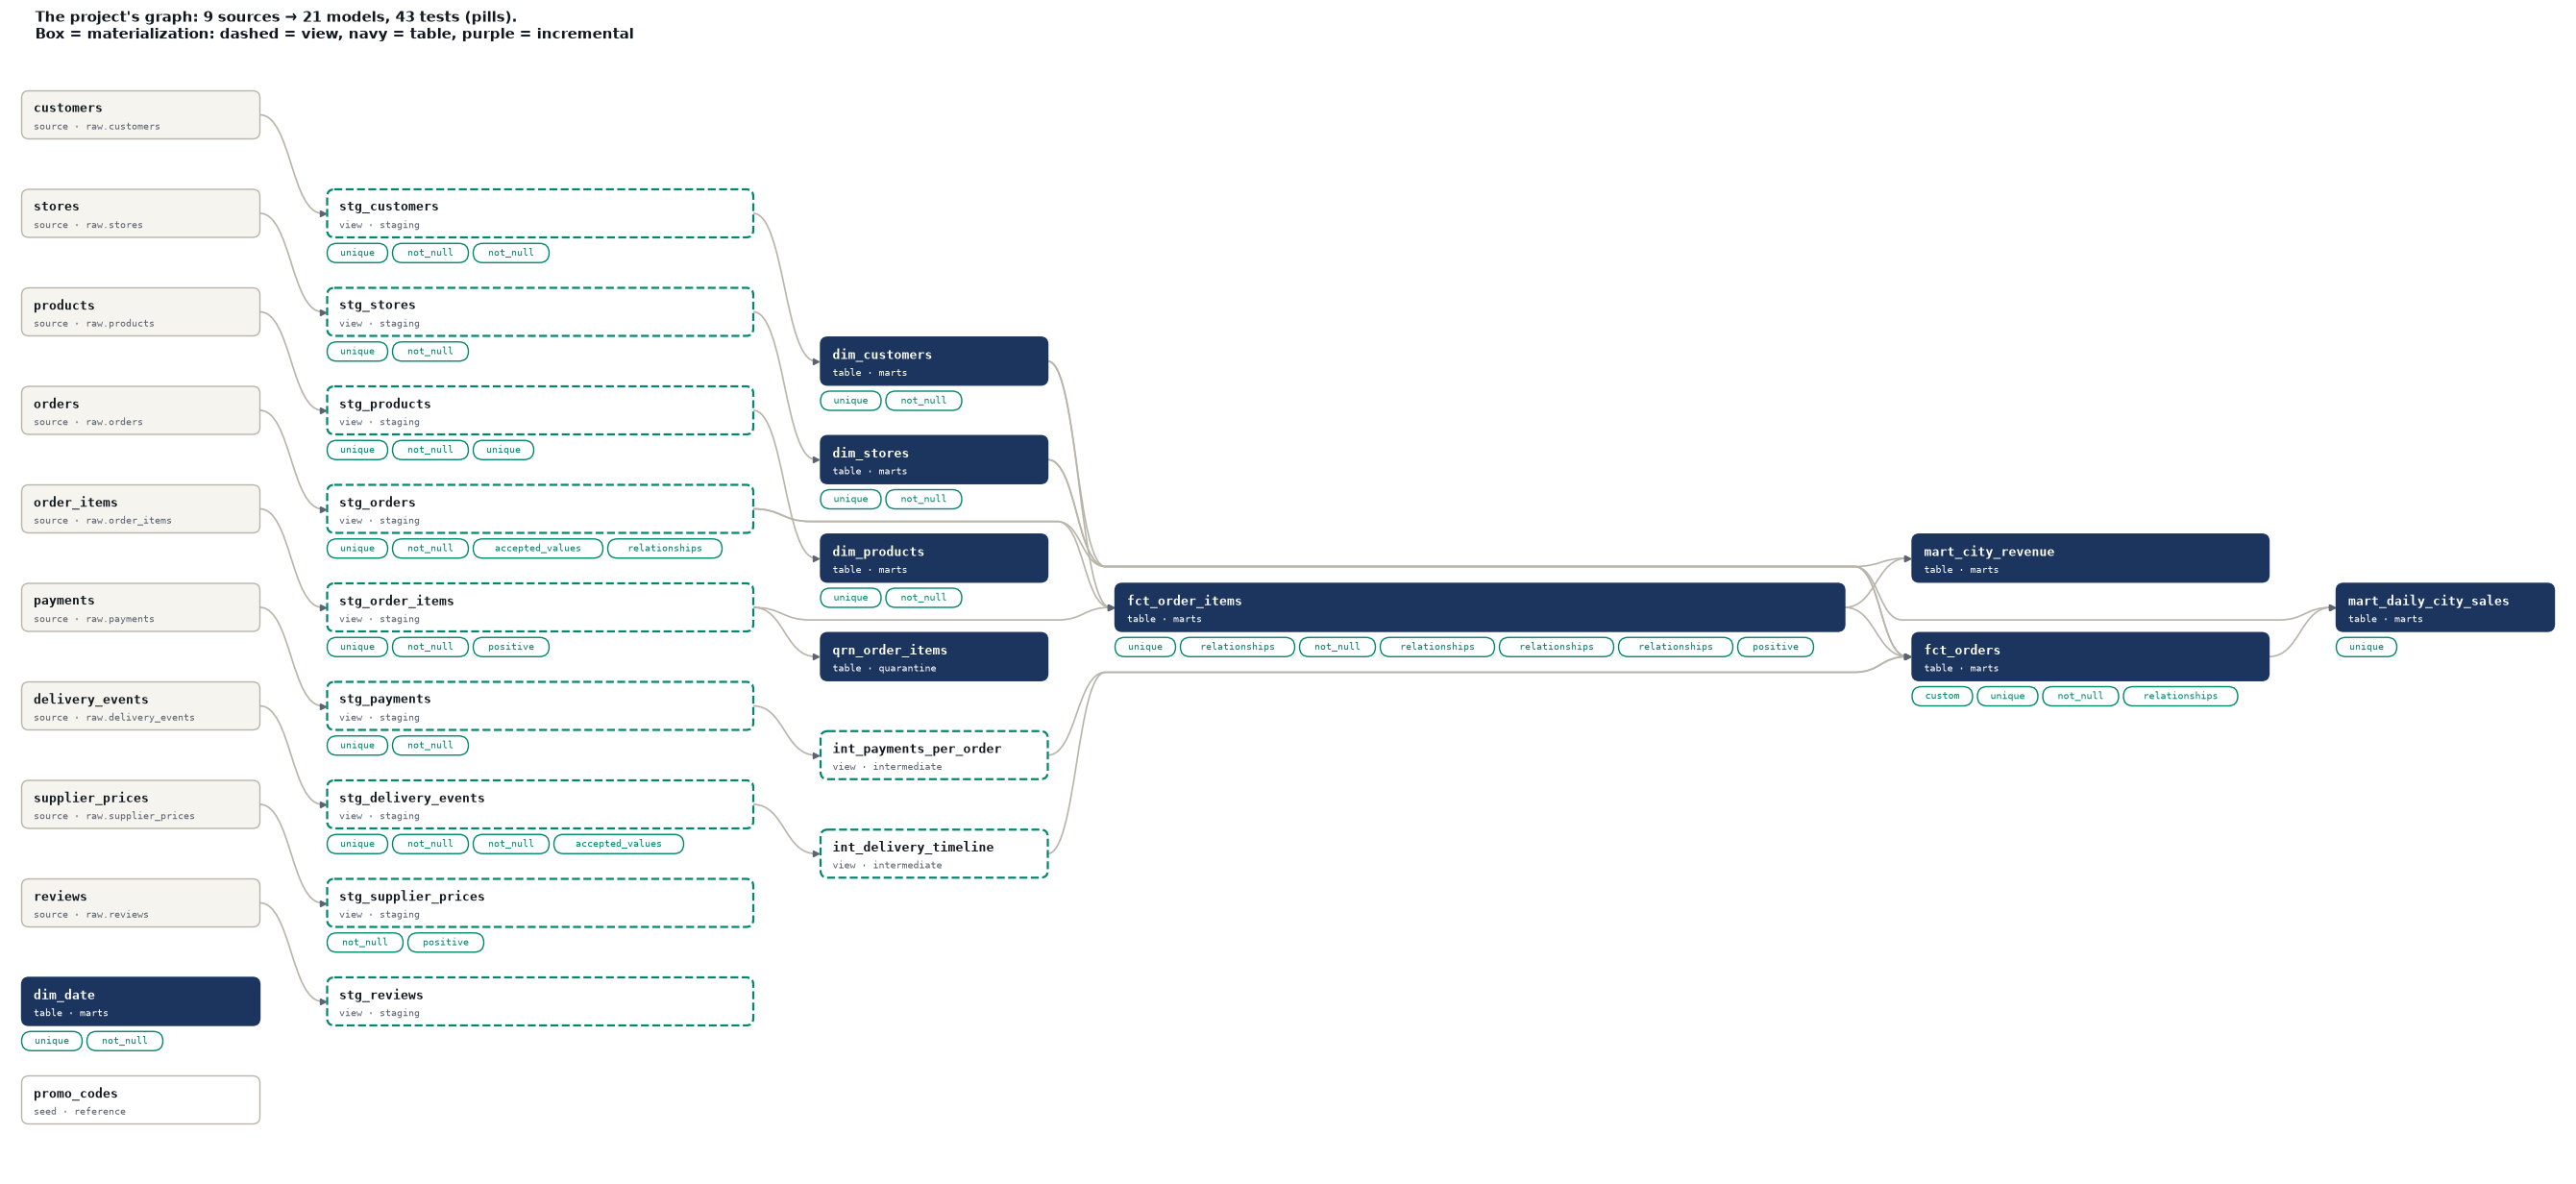

In [16]:
downstream = model_names("--select", "stg_orders+")
upstream = model_names("--select", "+mart_city_revenue")
print("stg_orders+       :", downstream)
print("+mart_city_revenue:", upstream)
V.dbt_graph(PROJ)

In [17]:
U.check("mart_city_revenue" in downstream and "stg_orders" in upstream, "your mart sits downstream of stg_orders")

✅ your mart sits downstream of stg_orders


🔍 You want to rename `status` in `stg_orders`. The first line of the output above is the list of models to check before
you do. That's why lineage matters on an ordinary Tuesday, not only in diagrams.

## ✱ Stretch · Split your mart by month

Add `month(f.order_date) as month` to `mart_city_revenue` so it has one row per city and month, then rebuild only it. How
many rows do you expect?

In [18]:
def stretch():
    MART.write_text("""select s.city, month(f.order_date) as month, round(sum(f.net_amount), 2) as revenue_sar
    from {{ ref('fct_order_items') }} f
    join {{ ref('dim_stores') }} s using (store_id)
    where f.order_status = 'delivered'
    group by all
    """, encoding="utf-8")
    dbt("build", "--select", "mart_city_revenue", quiet=True)
    display(sql("SELECT * FROM marts.mart_city_revenue ORDER BY city, month"))


try:
    stretch()
except NotImplementedError:
    print("✱ Optional: write stretch() above if you have time.")

,city,month,revenue_sar
0,Dammam,8,538596.84
1,Dammam,9,600239.76
2,Jeddah,8,970984.78
3,Jeddah,9,1062633.91
4,Riyadh,8,1579159.46
5,Riyadh,9,1748564.50


## Checkpoint

1. What would break if `mart_city_revenue` used `marts.fct_order_items` instead of `{{ ref('fct_order_items') }}`?
2. Why are staging models views and marts tables here?
3. What's the difference between `dbt build --select stg_orders+` and `dbt build --select +stg_orders`?

<details><summary>Answers</summary>

1. The SQL still works once the table exists, but dbt no longer sees the arrow: on a new database it may build the mart
   first and fail, and the lineage misses it.
2. Staging is light and should always show current raw data, so a saved query is enough. Marts are read all day by many
   people, so a stored result is worth the build time.
3. `stg_orders+` builds it and everything that reads it. `+stg_orders` builds it and everything it needs.

</details>

## Carry forward

Lab 3.3 adds tests to this project, and Lab 3.4 puts it in an orchestrator's graph. Both start from a fresh copy. dbt can
also load only new rows instead of rebuilding a big table (incremental models); you'll meet that later on the job.

Want more? `tools/dbt.ipynb`.